In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT


In [4]:
df = pd.read_csv("GSCR2026.csv")

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   str           
 3   Destination_Port           5000 non-null   str           
 4   Transport_Mode             5000 non-null   str           
 5   Product_Category           5000 non-null   str           
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   str           
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

In [49]:
df.isnull().sum()

Shipment_ID                  0
Date                         0
Origin_Port                  0
Destination_Port             0
Transport_Mode               0
Product_Category             0
Distance_km                  0
Weight_MT                    0
Fuel_Price_Index             0
Geopolitical_Risk_Score      0
Weather_Condition            0
Carrier_Reliability_Score    0
Lead_Time_Days               0
Disruption_Occurred          0
Total_Estimated_Cost         0
Risk_Category                0
dtype: int64

In [50]:
df.drop_duplicates(inplace=True)

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred,Total_Estimated_Cost,Risk_Category
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1,28702.01,WARNING
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1,78198.35,CRITICAL
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0,84805.47,STABLE
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1,50386.09,STABLE
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1,33530.91,STABLE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,SC-14995,2025-11-10,Rotterdam,Dubai,Rail,Perishables,13512.26,428.97,3.35,8.8,Fog,0.664,20.28,0,194427.86,STABLE
4996,SC-14996,2025-11-23,Dubai,Shanghai,Air,Perishables,2231.02,448.86,1.79,0.5,Clear,0.863,0.50,0,18175.34,STABLE
4997,SC-14997,2025-10-18,Antwerp,Busan,Rail,Pharmaceuticals,5253.72,473.41,1.37,3.0,Clear,0.962,4.41,0,34324.14,STABLE
4998,SC-14998,2025-01-29,Singapore,Dubai,Rail,Automotive,12328.31,199.35,3.45,4.4,Storm,0.819,31.18,1,85038.88,STABLE


1-Approximate Cost Calculation

In [35]:
#Approximate Cost Calculation
# Fixed base fee for every shipment (Operational overhead)
base_fee = 250

# Calculate total cost using vectorized NumPy multiplication for performance:
# Formula: (Distance * Fuel Index * (Weight / 100)) + Base Fee
df["Total_Estimated_Cost"] = np.multiply(
    np.multiply(df["Distance_km"], df["Fuel_Price_Index"]),
    df["Weight_MT"] / 100
) + base_fee

# Round the final cost to 2 decimal places for financial standard and readability
df["Total_Estimated_Cost"] = np.round(df["Total_Estimated_Cost"],2)

In [36]:
# Aggregate total costs by transport mode, sort from highest to lowest cost, and display results
mode_costs = df.groupby("Transport_Mode")["Total_Estimated_Cost"].sum().sort_values(ascending=False)
print(f"To base on Transport Mode total costs:{mode_costs}")

To base on Transport Mode total costs:Transport_Mode
Air     72162941.99
Sea     67800526.02
Rail    65156486.94
Road    64429650.88
Name: Total_Estimated_Cost, dtype: float64


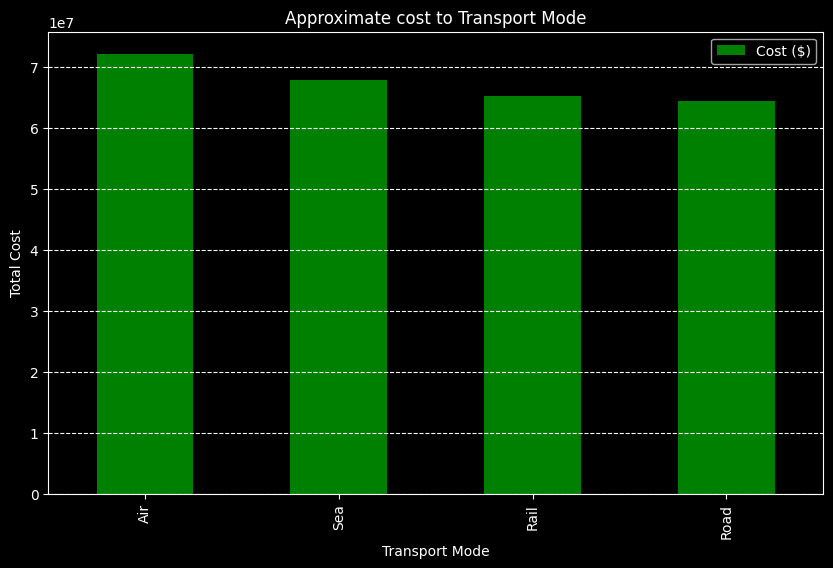

In [18]:
#Graphic Part
plt.figure(figsize=(10,6))

mode_costs.plot(kind="bar",color="green",label="Cost ($)")

plt.title("Approximate cost to Transport Mode")
plt.xlabel("Transport Mode")
plt.ylabel("Total Cost")
plt.legend()
plt.grid(axis="y", linestyle="--")
plt.savefig("Transport_Mode.svg", dpi=300)

plt.show()

2-Risk Categorization

In [19]:
#Risk Categorization

# Create a multi-tiered risk category using vectorized conditional logic (np.where)
df["Risk_Category"] = np.where(
    # Tier 1: High geopolitical risk AND an actual disruption = CRITICAL
    (df["Geopolitical_Risk_Score"]>=7) & (df["Disruption_Occurred"]==1),
    "CRITICAL",
    np.where(
        # Tier 2: Moderate geopolitical risk AND severe weather = WARNING
        (df["Geopolitical_Risk_Score"]>=5) & (df["Weather_Condition"].isin(["Hurricane", "Storm"])),
    "WARNING",
        # Tier 3: Default fallback state if no conditions are triggered
    "STABLE"
    )
)

In [20]:
#Analyze

# Compute the total frequency of shipments within each risk category
risk_counts = df["Risk_Category"].value_counts()

# Print the header and the categorical summary results
print("Risk Category Scatter")
print(risk_counts)

Risk Category Scatter
Risk_Category
STABLE      3421
CRITICAL    1152
WARNING      427
Name: count, dtype: int64


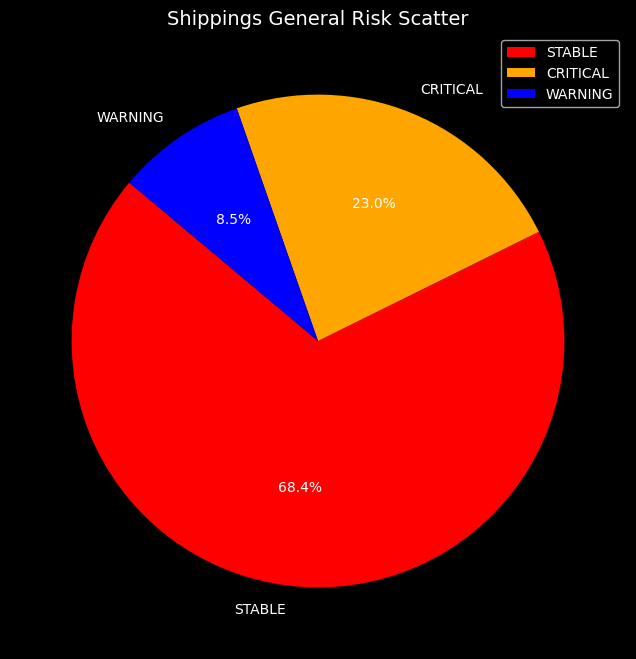

In [24]:
#Graphic Part
plt.figure(figsize=(8,8))
colors=["red","orange","blue"]

# startangle=140 rotates the pie chart by 140 degrees to optimize slice alignment and prevent overlapping labels
risk_counts.plot(kind="pie", autopct="%1.1f%%", colors=colors, startangle=140)

plt.title("Shippings General Risk Scatter", fontsize=14)
plt.ylabel("")
plt.legend(risk_counts.index, loc="upper right")
plt.savefig("Risk_Scatter.svg")

plt.show()

3-Carrier Reliability and Delay Analysis

In [26]:
#Efficiency analysis with using NumPy

# Analyze logistics efficiency by calculating average reliability and lead time per transport mode
efficiency_analysis = df.groupby("Transport_Mode").agg({
    "Carrier_Reliability_Score": np.mean,  # Average quality/reliability of the carriers
    "Lead_Time_Days": np.mean              # Average transit duration

}).reset_index()                           # Flatten the index for easier downstream plotting/analysis



In [27]:
#Analysis Part
print("Transport Mode Efficiency Analysis")
print(efficiency_analysis)

Transport Mode Efficiency Analysis
  Transport_Mode  Carrier_Reliability_Score  Lead_Time_Days
0            Air                   0.752698        1.644273
1           Rail                   0.762703       19.954253
2           Road                   0.750843       16.452306
3            Sea                   0.751794       39.802966


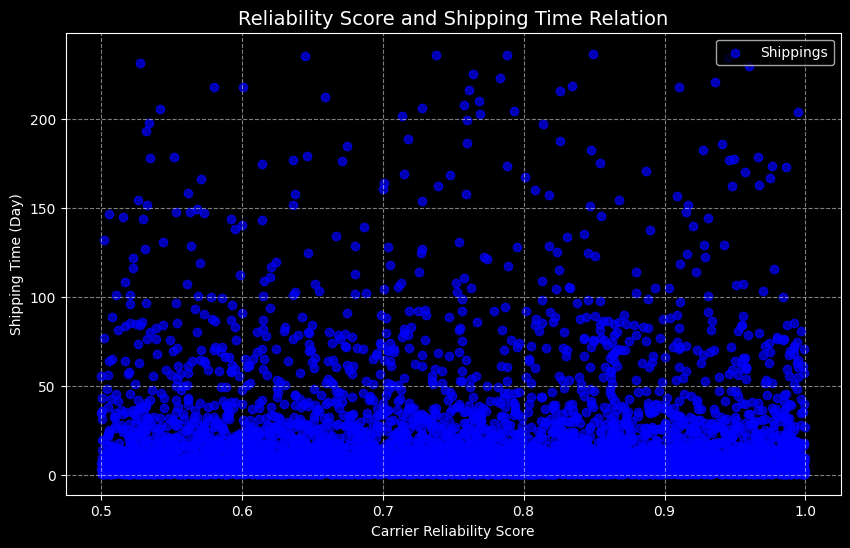

In [28]:
#Graphic Part

plt.figure(figsize=(10,6))
plt.scatter(df["Carrier_Reliability_Score"], df["Lead_Time_Days"], color="blue", label="Shippings",alpha=0.7)
#The alpha part allows us to reconfigure our opacity

plt.title("Reliability Score and Shipping Time Relation", fontsize=14)
plt.xlabel("Carrier Reliability Score")
plt.ylabel("Shipping Time (Day)")
plt.grid(True, linestyle="--",alpha=0.5)
plt.legend()

# dpi=300 ensures high-resolution rendering (300 dots per inch) for crisp, publication-ready graphics
plt.savefig("Reliability_Score.svg",dpi=300)

plt.show()

4-Time Series and Trend Analysis

In [31]:
# 1. Convert the 'Date' column from a string/object format to an active datetime object
df["Date"] = pd.to_datetime(df["Date"])

# 2. Resample the data by Month-End ("ME") and calculate the total number of shipments per month
monthly_shipments = df.resample("ME", on="Date").size()

# 3. Print the monthly volume distribution to verify historical trends
print("Monthly Shipment Size")
print(monthly_shipments)

Monthly Shipment Size
Date
2024-01-31    173
2024-02-29    195
2024-03-31    220
2024-04-30    229
2024-05-31    211
2024-06-30    208
2024-07-31    174
2024-08-31    199
2024-09-30    210
2024-10-31    215
2024-11-30    221
2024-12-31    200
2025-01-31    231
2025-02-28    187
2025-03-31    218
2025-04-30    213
2025-05-31    202
2025-06-30    186
2025-07-31    226
2025-08-31    214
2025-09-30    192
2025-10-31    221
2025-11-30    230
2025-12-31    225
Freq: ME, dtype: int64


<Figure size 640x480 with 0 Axes>

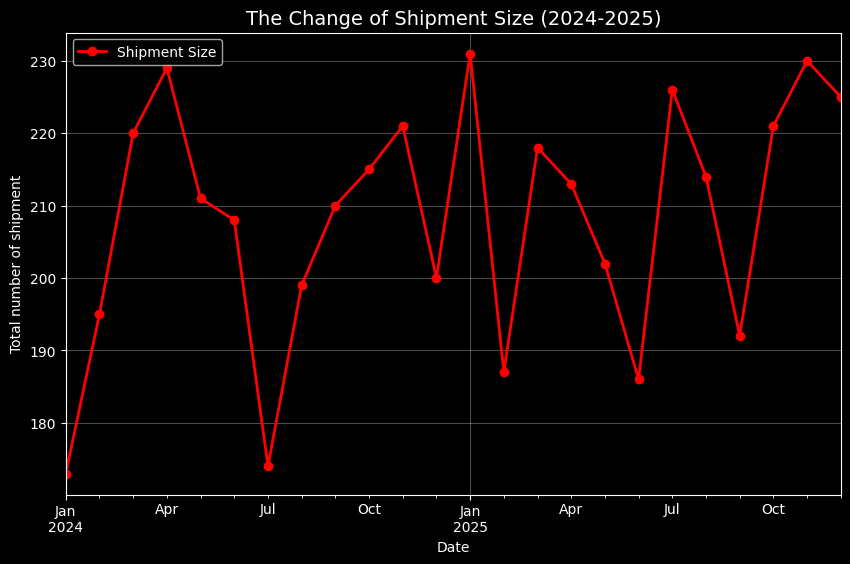

In [34]:
#Graphic Part
plt.clf()
plt.figure(figsize=(10,6))
monthly_shipments.plot(kind="line", marker="o", color="red", linewidth=2, label="Shipment Size")

plt.title("The Change of Shipment Size (2024-2025)", fontsize =14)
plt.xlabel("Date")
plt.ylabel("Total number of shipment")
# alpha=0.3 sets gridline transparency to 30%, making them faint so they don't distract from the main plot line
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig("Shipment_Size.svg",dpi=300)

plt.show()